In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('data/zestaw_nr_1_11_16.csv')
df.loc[df['freq_y']>100]=0
df.loc[df['freq_z']>100]=0
df.loc[df['freq_x']>100]=0


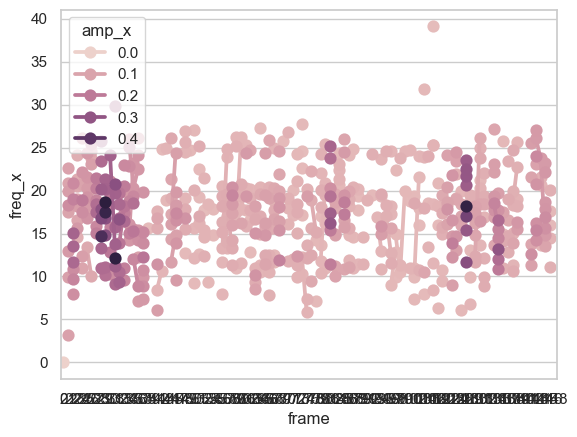

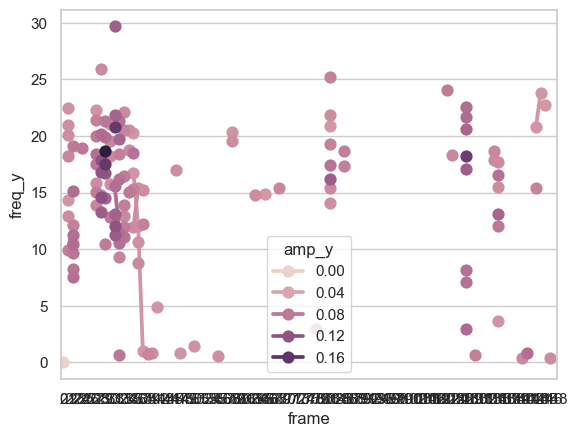

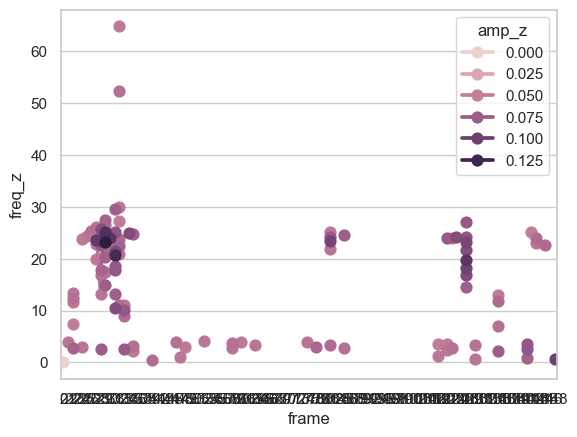

In [13]:



f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_x',hue='amp_x',errorbar=None)

f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_y',hue='amp_y',errorbar=None)

f,ax=plt.subplots()
ax=sns.pointplot(data=df,x='frame',y='freq_z',hue='amp_z',errorbar=None)

AttributeError: 'NoneType' object has no attribute 'get_bbox'

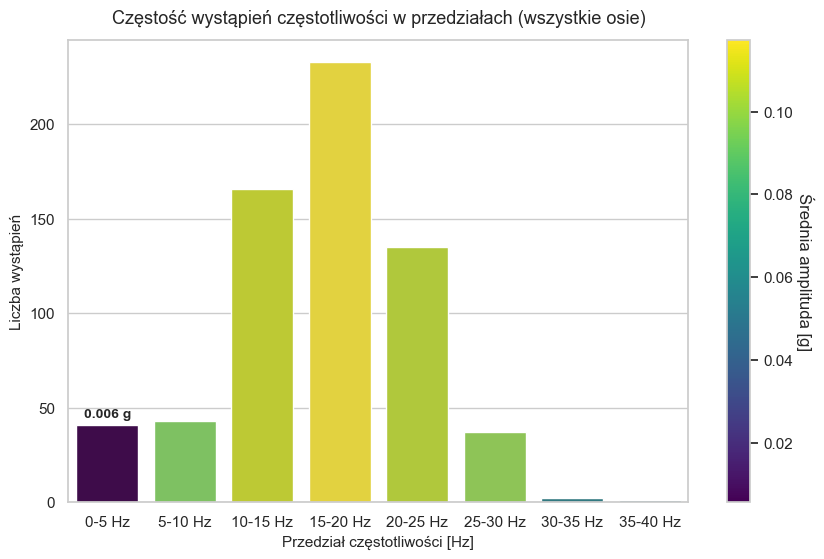

In [21]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors



#1. Przekształcenie danych ze wszystkich osi (X, Y, Z) do wspólnych kolumn
'''df_long = pd.concat([
    df[['freq_x', 'amp_x']].rename(columns={'freq_x': 'freq', 'amp_x': 'amp'}).assign(axis='X'),
    df[['freq_y', 'amp_y']].rename(columns={'freq_y': 'freq', 'amp_y': 'amp'}).assign(axis='Y'),
    df[['freq_z', 'amp_z']].rename(columns={'freq_z': 'freq', 'amp_z': 'amp'}).assign(axis='Z')
]).dropna()'''

df_long = df[['freq_x', 'amp_x']].rename(columns={'freq_x': 'freq', 'amp_x': 'amp'}).dropna()

# 2. Podział częstotliwości na przedziały (koszyki)
bins = [0, 5, 10, 15, 20, 25, 30,35,40]
labels = ['0-5 Hz', '5-10 Hz', '10-15 Hz', '15-20 Hz', '20-25 Hz', '25-30 Hz','30-35 Hz','35-40 Hz']
df_long['freq_bin'] = pd.cut(df_long['freq'], bins=bins, labels=labels, right=True, include_lowest=True)

# 3. Agregacja: zliczenie wystąpień oraz obliczenie średniej amplitudy dla każdego zakresu
summary = df_long.groupby('freq_bin', observed=False).agg(
    count=('freq', 'count'),
    mean_amp=('amp', 'mean'),
).reset_index()

# Uzupełnienie NaN zerami dla przedziałów bez żadnych wystąpień
summary['mean_amp'] = summary['mean_amp'].fillna(0)

# 4. Przygotowanie mapy kolorów dla amplitudy
norm = mcolors.Normalize(vmin=summary['mean_amp'].min(), vmax=summary['mean_amp'].max())
cmap = cm.viridis  # inne dobre opcje: 'plasma', 'inferno', 'magma', 'coolwarm'
colors = [cmap(norm(val)) for val in summary['mean_amp']]

# 5. Rysowanie wykresu
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=summary,
    x='freq_bin',
    y='count',
    hue='freq_bin',
    palette=colors,
    legend=False,
    ax=ax
)

# Dodanie paska kolorów (colorbar) reprezentującego amplitudę
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Średnia amplituda [g]', rotation=270, labelpad=15)

# Opisy osi i tytuł
ax.set_title('Częstość wystąpień częstotliwości w przedziałach (wszystkie osie)', fontsize=13, pad=12)
ax.set_xlabel('Przedział częstotliwości [Hz]', fontsize=11)
ax.set_ylabel('Liczba wystąpień', fontsize=11)

# Opcjonalnie: dodanie dokładnych wartości liczbowych nad słupkami
'''for container in ax.containers:
    ax.bar_label(container,summary['mean_amp'],padding=3)'''

amp_labels = [f"{val:.3f} g" if count > 0 else "0" for val, count in zip(summary['mean_amp'], summary['count'])]

# Dodanie etykiet nad słupkami
for container in ax.containers:
    ax.bar_label(container, labels=amp_labels, padding=3, fontsize=10, fontweight='bold')

# Zwiększenie górnego limitu osi Y o 10%, aby etykiety nie dotykały górnej ramki wykresu
ax.set_ylim(0, summary['count'].max() * 1.1)

plt.tight_layout()
plt.show()